# 꽃 사진을 만드는 Diffusion: DDPM 처음부터 구현하기

**목표:** 실제 꽃 사진에 노이즈를 섞고, 그 노이즈를 예측하는 모델을 학습한 뒤,
순수한 잡음에서 새로운 **64 × 64 RGB 꽃 이미지**를 생성합니다.
사전 학습 모델이나 diffusion 전용 라이브러리 없이 PyTorch로 직접 구현합니다.

데이터는 MNIST/CIFAR 대신 **Oxford Flowers 102**를 사용합니다.
꽃잎의 색, 모양, 배경이 다양해서 원본과 생성 결과를 관찰하기 좋습니다.
이 모델은 꽃 이름이나 문장을 입력받지 않는 **무조건부 생성 모델**입니다.

| 순서 | 실습 내용 | 관찰할 내용 |
|---|---|---|
| 1–3 | 환경 설정 → 꽃 사진 다운로드 → 원본 확인 | RGB 텐서와 정규화 |
| 4–5 | 노이즈 스케줄 → 정방향 확산 | 사진이 잡음으로 변하는 과정 |
| 6–8 | 시간 임베딩 → U-Net → 역방향 확산 | 모델이 예측하는 것은 무엇인가? |
| 9–11 | 사전 점검 → 학습 → 손실/샘플 비교 | 학습이 실제 생성에 미치는 영향 |
| 12–14 | 새 이미지 → GIF → 저장 모델 재사용 | 잡음이 이미지로 바뀌는 과정 |

**실행 방법:** Python 커널을 선택한 후 위에서 아래로 실행합니다.
먼저 `RUN_MODE = "smoke"`로 전체 흐름을 확인하고, `"train"`으로 바꾼 뒤
커널을 재시작하여 본학습을 진행하세요. smoke 모드는 좋은 이미지를 만드는 학습이 아닙니다.
본학습도 처음 몇 epoch에는 얼룩이 나올 수 있으며, 선명한 꽃은 더 긴 학습이 필요합니다.


## 1-1. 설치와 커널 확인

권장 환경은 **Python 3.12 + CUDA를 사용할 수 있는 PyTorch + Jupyter 커널**입니다.
VS Code 우측 상단에서 프로젝트의 `.venv` 커널을 선택하세요.
이 프로젝트에서는 `../../.venv/Scripts/python.exe`에 해당합니다.

아래 설치 명령은 필요한 경우에만 주석을 해제합니다. 이미 GPU용 PyTorch가 있다면
덮어쓸 필요가 없습니다. GPU용 설치 명령은 [PyTorch 공식 설치 페이지](https://pytorch.org/get-started/locally/)에서
환경에 맞게 선택하세요. `scipy`는 Flowers102의 `.mat` 메타데이터를 읽는 데 필요합니다.
설치 후에는 커널을 재시작합니다.


In [1]:
# 작업 1: 라이브러리가 없는 커널에서만 주석을 해제하여 설치합니다.
# %pip install torch torchvision matplotlib pillow scipy tqdm

# 작업 2: 현재 선택한 커널의 Python 경로를 확인합니다.
import sys
print("현재 Python:", sys.executable)


현재 Python: c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Scripts\python.exe


## 1-2. 라이브러리, 재현성, 장치 설정

난수 시드를 고정하면 비교 실험이 쉬워집니다. 다만 GPU 연산과 소프트웨어 버전이
달라지면 완전히 같은 결과를 보장하지는 않습니다. CUDA가 없으면 CPU로 실행됩니다.
CPU에서는 본학습보다 smoke 모드로 원리와 코드 흐름을 먼저 확인하는 것이 좋습니다.


In [3]:
# 작업 1: 데이터 처리, 신경망, 시각화에 사용할 도구를 불러옵니다.
import copy
import math
import random
import time
from pathlib import Path
from itertools import islice

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import ConcatDataset, DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
from tqdm.auto import tqdm
from IPython.display import display

# 작업 2: Python, NumPy, PyTorch의 난수 시작점을 맞춥니다.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 작업 3: CUDA 지원 여부와 사용할 장치를 확인합니다.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print("PyTorch:", torch.__version__, "| 장치:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CPU 실행: 전체 학습과 400단계 이미지 생성은 오래 걸릴 수 있습니다.")


PyTorch: 2.14.0+cu130 | 장치: cuda
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU


## 1-3. 실험 설정과 저장 위치

| 설정 | smoke | train |
|---|---|---|
| 목적 | 모든 단계가 연결되는지 확인 | 실제 꽃 분포 학습 |
| 데이터 수 | 128장 | 전체 데이터 |
| 학습 | 1 epoch, 최대 2 step | 50 epoch, 모든 배치 |
| 채널 폭 | 32 | 64 |

두 모드 모두 **64 × 64 / 400 diffusion step**을 사용합니다. `TIMESTEPS`는 이미지 한 장을
복원하는 단계 수이고, optimizer의 학습 step 수와 다릅니다. 학습은 무작위 시간 하나만
뽑으므로 배치마다 모델을 400번 실행하지 않습니다.

CUDA 메모리가 부족하면 `BATCH_SIZE`를 16 또는 8로 낮추세요. 본학습 시간이 길면
먼저 epoch 수를 낮추고, 결과를 확인한 뒤 체크포인트에서 이어서 학습하세요.
모든 경로는 현재 작업 디렉터리 기준이며 마지막에 출력됩니다.


In [4]:
# 작업 1: 빠른 확인 또는 본학습을 선택합니다.
RUN_MODE = "train"  # 처음에는 "smoke"로 바꿔 실행해 보세요.
assert RUN_MODE in {"smoke", "train"}
IMAGE_SIZE = 64
TIMESTEPS = 400
BATCH_SIZE = 32 if device.type == "cuda" else 8
BASE_CHANNELS = 32 if RUN_MODE == "smoke" else 64
EPOCHS = 1 if RUN_MODE == "smoke" else 50
MAX_IMAGES = 128 if RUN_MODE == "smoke" else None
MAX_STEPS_PER_EPOCH = 2 if RUN_MODE == "smoke" else None
LEARNING_RATE = 2e-4
EMA_DECAY = 0.995
PREVIEW_EVERY = 10
NUM_WORKERS = 0  # Windows 노트북에서 프로세스 생성 문제를 피하는 기본값입니다.

# 작업 2: 데이터 및 실험별 결과 폴더를 생성합니다.
DATA_DIR = Path("data")
OUTPUT_DIR = Path("runs") / f"flowers_ddpm_{RUN_MODE}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = OUTPUT_DIR / "last.pt"
RESUME = False  # 기존 last.pt에서 이어서 하려면 True, EPOCHS는 목표 총 epoch입니다.
print("데이터:", DATA_DIR.resolve())
print("결과:", OUTPUT_DIR.resolve())


데이터: C:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\02_self_study\generative\data
결과: C:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\02_self_study\generative\runs\flowers_ddpm_train


## 2. 꽃 사진 다운로드와 전처리

[Oxford 공식 데이터](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/index.html)는
102종의 꽃 사진으로 구성되어 있으며 첫 실행 시 이미지 압축파일 약 330MB와 메타데이터를
다운로드합니다. 압축 해제 공간도 필요합니다. smoke 모드도 원본 다운로드 크기는 같습니다.
이후에는 로컬 파일을 재사용합니다.

이 실습은 분류 정확도나 FID를 평가하지 않고 **생성 원리를 학습하는 데 목적**이 있으므로
공식 train/val/test 이미지를 합쳐 사용하고 분류 라벨은 무시합니다.
따라서 뒤의 원본 비교는 학습 데이터와의 시각적 비교이며 일반화 성능 평가가 아닙니다.
평가 실험을 추가하려면 합치기 전에 별도 holdout을 남겨야 합니다.

전처리는 `RGB → 짧은 변 resize → 중앙 crop → 좌우 반전 → 텐서 → [-1, 1] 정규화`입니다.
중앙 crop은 일부 가장자리를 자를 수 있지만 꽃의 비율은 유지합니다.
다운로드가 실패하면 네트워크를 확인한 뒤 이 셀을 다시 실행하세요.


In [5]:
# 작업 1: 세 색상 채널을 같은 범위로 변환하고 간단한 증강을 적용합니다.
transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,) * 3, (0.5,) * 3),
])

# 작업 2: 공식 split을 읽습니다. 다운로드된 파일은 다음 split에서도 공유됩니다.
parts = [
    datasets.Flowers102(root=DATA_DIR, split=split, download=True, transform=transform)
    for split in ("train", "val", "test")
]
dataset = ConcatDataset(parts)
if MAX_IMAGES is not None:
    indices = torch.randperm(len(dataset), generator=torch.Generator().manual_seed(SEED))
    dataset = Subset(dataset, indices[:MAX_IMAGES].tolist())

# 작업 3: 매 epoch마다 이미지 순서를 섞고 마지막 작은 배치도 사용합니다.
loader = DataLoader(
    dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
    pin_memory=device.type == "cuda", drop_last=False,
)
print("공식 split별 수:", [len(part) for part in parts])
print(f"학습 이미지 {len(dataset):,}장 | epoch당 {len(loader):,}개 배치")


공식 split별 수: [1020, 1020, 6149]
학습 이미지 8,189장 | epoch당 256개 배치


## 3. 원본 이미지와 텐서 확인

신경망에는 `[배치, RGB 채널, 높이, 너비]` 순서의 텐서를 넣습니다.
학습 범위 `[-1, 1]`을 화면 표시 범위 `[0, 1]`로 되돌려 원본 사진을 확인합니다.
아래 `show_images`는 이후 학습 샘플과 생성 결과에도 사용합니다.


배치 크기: (32, 3, 64, 64)
픽셀 범위: -1.0 ~ 1.0


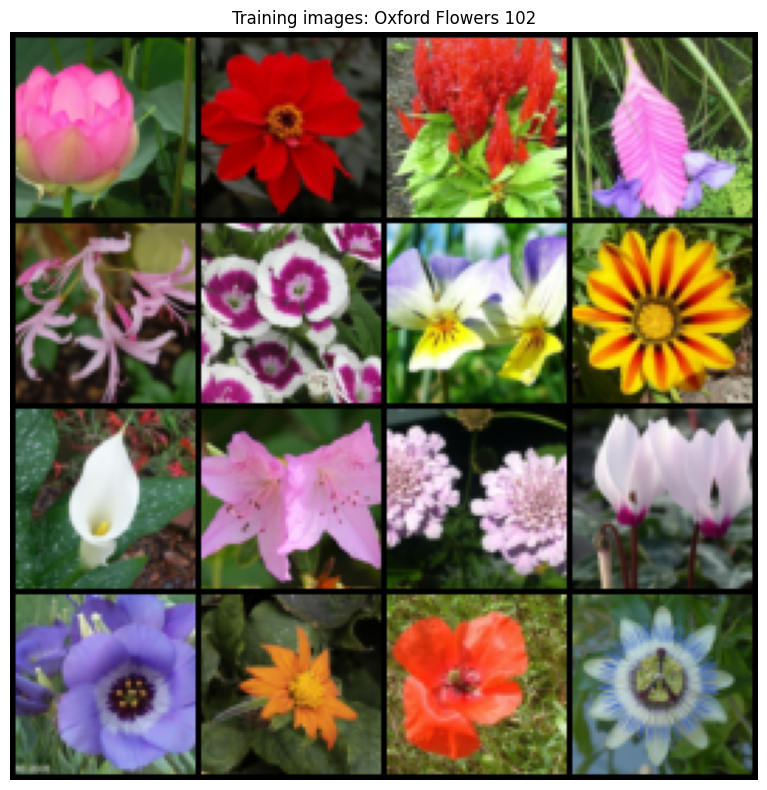

In [6]:
# 작업 1: 정규화 역변환과 이미지 격자 표시 함수를 정의합니다.
def to_display(images):
    return (images.detach().float().cpu().clamp(-1, 1) + 1) / 2


def show_images(images, title, nrow=4):
    grid = make_grid(to_display(images), nrow=nrow, padding=2)
    plt.figure(figsize=(8, 8))
    plt.imshow(grid.permute(1, 2, 0).numpy())
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


# 작업 2: 실제 배치의 크기, 값 범위, 사진을 확인합니다.
real_images, _ = next(iter(loader))
assert real_images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert -1 <= real_images.min() and real_images.max() <= 1
print("배치 크기:", tuple(real_images.shape))
print("픽셀 범위:", real_images.min().item(), "~", real_images.max().item())
show_images(real_images[:16], "Training images: Oxford Flowers 102")


## 4. Diffusion 스케줄: 얼마나 많은 노이즈를 섞을까?

시간이 지날수록 원본의 비중을 줄이고 가우시안 잡음의 비중을 늘립니다.
작은 step 수에서도 마지막 시점이 충분히 잡음에 가까워지도록 **cosine 스케줄**을 사용합니다.

$$\alpha_t = 1-\beta_t, \qquad \bar\alpha_t = \prod_{s=0}^{t}\alpha_s$$

`beta`는 한 단계에서 추가할 노이즈의 크기, `alpha_bar`는 원본 신호가 남은 누적 비율입니다.
코드에서는 시간 인덱스가 `0 … T-1`이므로 `t=0`에도 아주 적은 노이즈가 있습니다.
**노이즈가 전혀 없는 원본**은 별도의 `x_0` 텐서로 다룹니다.


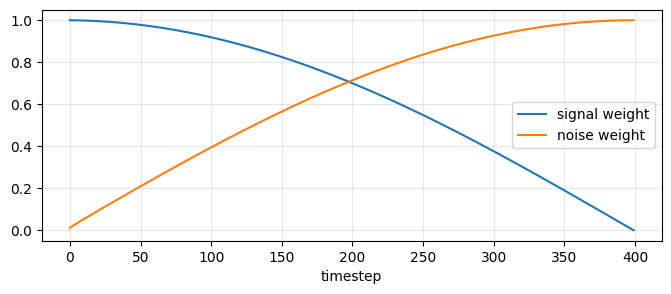

In [7]:
# 작업 1: cosine 누적 신호에서 단계별 beta를 계산합니다.
def make_schedule(timesteps, target_device):
    edges = torch.linspace(0, timesteps, timesteps + 1, dtype=torch.float64)
    cumulative = torch.cos(((edges / timesteps + 0.008) / 1.008) * math.pi / 2).square()
    cumulative = cumulative / cumulative[0]
    betas = (1 - cumulative[1:] / cumulative[:-1]).clamp(1e-5, 0.999).float()
    alphas = 1 - betas
    alpha_bars = torch.cumprod(alphas, dim=0)
    previous = torch.cat([torch.ones(1), alpha_bars[:-1]])
    return {
        "beta": betas.to(target_device),
        "alpha": alphas.to(target_device),
        "alpha_bar": alpha_bars.to(target_device),
        "alpha_bar_prev": previous.to(target_device),
        "posterior_variance": (betas * (1 - previous) / (1 - alpha_bars)).to(target_device),
    }


# 작업 2: 각 이미지의 timestep에 해당하는 값을 [B,1,1,1]로 꺼냅니다.
def extract(values, t):
    return values[t].view(-1, 1, 1, 1)


schedule = make_schedule(TIMESTEPS, device)
assert torch.all(schedule["alpha_bar"][1:] < schedule["alpha_bar"][:-1])
assert schedule["alpha_bar"][-1] < 1e-4

# 작업 3: 누적 신호와 노이즈의 비중을 비교합니다.
signal = schedule["alpha_bar"].cpu()
plt.figure(figsize=(8, 3))
plt.plot(signal.sqrt(), label="signal weight")
plt.plot((1 - signal).sqrt(), label="noise weight")
plt.xlabel("timestep")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 5. 정방향 확산: 꽃 사진에 노이즈 추가하기

반복해서 노이즈를 넣는 대신 아래 식으로 원하는 시점의 이미지를 **한 번에** 만듭니다.

$$x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon,
\qquad \epsilon\sim\mathcal N(0,I)$$

학습할 때도 같은 식을 씁니다. 아래 그림은 같은 원본과 같은 잡음을 사용하여
시점별 노이즈 강도를 비교합니다. 실제 순차 확산 궤적을 시뮬레이션한 그림은 아닙니다.


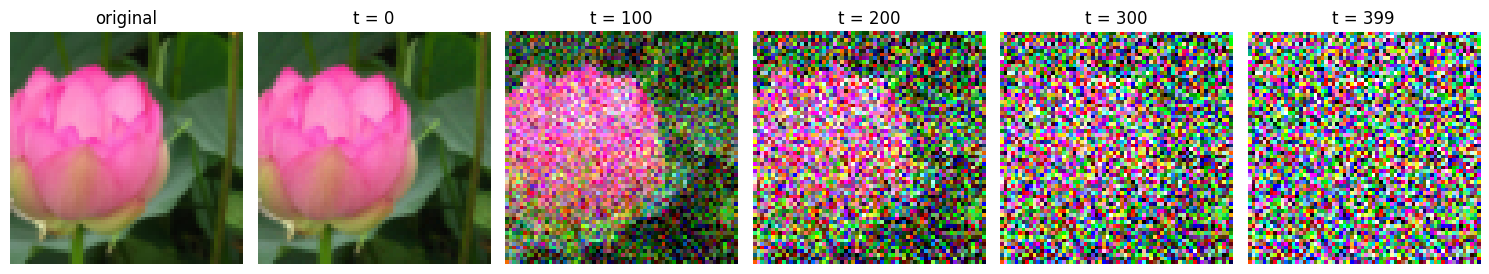

In [8]:
# 작업 1: 원본, timestep, 정답 잡음으로 noisy image를 만듭니다.
def add_noise(x0, t, noise, diffusion_schedule):
    alpha_bar = extract(diffusion_schedule["alpha_bar"], t)
    return alpha_bar.sqrt() * x0 + (1 - alpha_bar).sqrt() * noise


# 작업 2: 서로 다른 시점에서 동일한 사진이 얼마나 가려지는지 확인합니다.
demo_x0 = real_images[:1].to(device)
demo_noise = torch.randn_like(demo_x0)
demo_steps = [0, TIMESTEPS // 4, TIMESTEPS // 2, 3 * TIMESTEPS // 4, TIMESTEPS - 1]
fig, axes = plt.subplots(1, len(demo_steps) + 1, figsize=(15, 3))
axes[0].imshow(to_display(demo_x0)[0].permute(1, 2, 0))
axes[0].set_title("original")
for ax, step in zip(axes[1:], demo_steps):
    xt = add_noise(demo_x0, torch.tensor([step], device=device), demo_noise, schedule)
    ax.imshow(to_display(xt)[0].permute(1, 2, 0))
    ax.set_title(f"t = {step}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 6-1. 시간 임베딩과 Residual Block

동일한 얼룩도 노이즈가 적은 시점과 많은 시점에서는 해석이 달라집니다.
따라서 모델에는 사진뿐 아니라 **현재 timestep**도 알려 줍니다.
Sinusoidal embedding은 정수 시간을 sin/cos 벡터로 바꾸고,
Residual Block은 이 정보를 이미지 특징에 더합니다.

`GroupNorm`은 배치가 작아도 쓸 수 있습니다. skip connection은 입력 특징을
다음 층으로 전달해 깊은 모델의 학습을 돕습니다.


In [ ]:
# 작업 1: 각 timestep을 주파수가 다른 sin/cos 벡터로 표현합니다.
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dimension):
        super().__init__()
        half = dimension // 2
        frequencies = torch.exp(-math.log(10000) * torch.arange(half) / (half - 1))
        self.register_buffer("frequencies", frequencies)

    def forward(self, t):
        angles = t.float()[:, None] * self.frequencies[None, :]
        return torch.cat([angles.sin(), angles.cos()], dim=-1)


# 작업 2: 이미지 특징에 시간 정보를 주입하고 잔차 경로를 더합니다.
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dimension):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.GroupNorm(8, in_channels), nn.SiLU(),
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
        )
        self.time_projection = nn.Sequential(nn.SiLU(), nn.Linear(time_dimension, out_channels))
        self.conv2 = nn.Sequential(
            nn.GroupNorm(8, out_channels), nn.SiLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
        )
        self.skip = nn.Conv2d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()

    def forward(self, x, time_embedding):
        h = self.conv1(x)
        h = h + self.time_projection(time_embedding)[:, :, None, None]
        return self.conv2(h) + self.skip(x)


## 6-2. 저해상도 Attention과 작은 U-Net

U-Net은 이미지를 줄이면서 전체 모양을 보고, 다시 키우면서 세부 정보를 복원합니다.
encoder 특징을 decoder에 연결하면 줄어드는 과정에서 놓친 공간 정보를 되살릴 수 있습니다.
16 × 16 특징에서만 attention을 사용해 멀리 있는 꽃잎 간의 관계를 보게 합니다.

구조: `64² → 32² → 16² + attention → 32² → 64²`.
**출력은 RGB 사진이 아니라 입력에 섞였던 노이즈의 추정치**이며,
가우시안 잡음은 음수와 양수 모두 가능하므로 마지막에 sigmoid/tanh를 붙이지 않습니다.


In [ ]:
# 작업 1: 공간 위치 간 관계를 보는 self-attention을 정의합니다.
class SpatialAttention(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.norm = nn.GroupNorm(8, channels)
        self.attention = nn.MultiheadAttention(channels, num_heads=4, batch_first=True)

    def forward(self, x):
        batch, channels, height, width = x.shape
        tokens = self.norm(x).flatten(2).transpose(1, 2)
        attended, _ = self.attention(tokens, tokens, tokens, need_weights=False)
        return x + attended.transpose(1, 2).reshape(batch, channels, height, width)


# 작업 2: 시간 임베딩을 모든 residual block에 전달하는 U-Net을 구성합니다.
class SmallUNet(nn.Module):
    def __init__(self, base_channels=64):
        super().__init__()
        c = base_channels
        time_dimension = c * 4
        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(c), nn.Linear(c, time_dimension), nn.SiLU(),
            nn.Linear(time_dimension, time_dimension),
        )
        self.input_conv = nn.Conv2d(3, c, 3, padding=1)
        self.encoder1 = ResidualBlock(c, c, time_dimension)
        self.down1 = nn.Conv2d(c, c * 2, 4, stride=2, padding=1)
        self.encoder2 = ResidualBlock(c * 2, c * 2, time_dimension)
        self.down2 = nn.Conv2d(c * 2, c * 4, 4, stride=2, padding=1)
        self.middle1 = ResidualBlock(c * 4, c * 4, time_dimension)
        self.attention = SpatialAttention(c * 4)
        self.middle2 = ResidualBlock(c * 4, c * 4, time_dimension)
        self.up2 = nn.Conv2d(c * 4, c * 2, 3, padding=1)
        self.decoder2 = ResidualBlock(c * 4, c * 2, time_dimension)
        self.up1 = nn.Conv2d(c * 2, c, 3, padding=1)
        self.decoder1 = ResidualBlock(c * 2, c, time_dimension)
        self.output = nn.Sequential(nn.GroupNorm(8, c), nn.SiLU(), nn.Conv2d(c, 3, 3, padding=1))

    def forward(self, x, t):
        embedding = self.time_embedding(t)
        skip1 = self.encoder1(self.input_conv(x), embedding)
        skip2 = self.encoder2(self.down1(skip1), embedding)
        h = self.middle1(self.down2(skip2), embedding)
        h = self.middle2(self.attention(h), embedding)
        h = self.up2(F.interpolate(h, size=skip2.shape[-2:], mode="nearest"))
        h = self.decoder2(torch.cat([h, skip2], dim=1), embedding)
        h = self.up1(F.interpolate(h, size=skip1.shape[-2:], mode="nearest"))
        h = self.decoder1(torch.cat([h, skip1], dim=1), embedding)
        return self.output(h)


## 7. 역방향 확산 한 단계: 노이즈 예측에서 이미지 복원으로

예측 잡음 $\epsilon_\theta(x_t,t)$에서 원본을 먼저 추정합니다.

$$\hat x_0 = \frac{x_t-\sqrt{1-\bar\alpha_t}\epsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}}$$

원본 범위에 맞게 $\hat x_0$를 `[-1, 1]`로 제한한 뒤,
DDPM posterior의 평균과 분산으로 이전 이미지를 샘플링합니다.

$$\mu_t=\frac{\beta_t\sqrt{\bar\alpha_{t-1}}}{1-\bar\alpha_t}\hat x_0
+\frac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}x_t$$
$$\tilde\beta_t=\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\beta_t,\qquad
x_{t-1}=\mu_t+\sqrt{\tilde\beta_t}z$$

코드의 첫 단계에는 $\bar\alpha_{-1}=1$을 사용합니다. 마지막 복원(`t=0`)에서는
새 잡음을 추가하지 않습니다. 정확한 노이즈를 아는 **교사 복원**과,
모델이 노이즈를 추측하는 **새 이미지 생성**은 구분해야 합니다.


In [ ]:
# 작업 1: 예측한 노이즈로 원본의 추정치를 구합니다.
def predict_x0(xt, t, predicted_noise, diffusion_schedule):
    alpha_bar = extract(diffusion_schedule["alpha_bar"], t)
    return (xt - (1 - alpha_bar).sqrt() * predicted_noise) / alpha_bar.sqrt()


# 작업 2: posterior 평균을 구하고 마지막 단계를 제외하고 잡음을 추가합니다.
def reverse_step(xt, t, predicted_noise, diffusion_schedule, noise):
    beta = extract(diffusion_schedule["beta"], t)
    alpha = extract(diffusion_schedule["alpha"], t)
    alpha_bar = extract(diffusion_schedule["alpha_bar"], t)
    previous = extract(diffusion_schedule["alpha_bar_prev"], t)
    x0_estimate = predict_x0(xt, t, predicted_noise, diffusion_schedule).clamp(-1, 1)
    mean = (
        beta * previous.sqrt() / (1 - alpha_bar) * x0_estimate
        + alpha.sqrt() * (1 - previous) / (1 - alpha_bar) * xt
    )
    variance = extract(diffusion_schedule["posterior_variance"], t)
    nonzero = (t > 0).float().view(-1, 1, 1, 1)
    return mean + nonzero * variance.clamp(min=0).sqrt() * noise


## 8. 순수 잡음에서 시작하는 전체 생성 함수

표준정규분포에서 시작하여 `T-1 → … → 0` 순서로 모델을 반복 호출합니다.
학습과 달리 생성은 **모든 diffusion step을 거치므로 느립니다**.
같은 seed는 초기 잡음과 단계별 잡음까지 고정하여 epoch별 비교를 돕습니다.
샘플링 난수는 전용 generator로 관리하므로 학습 난수 흐름을 바꾸지 않습니다.

중간 상태를 CPU에 기록해 나중에 GIF로 만듭니다.
초반 상태는 표시할 때만 픽셀을 잘라 보여주며, 내부 확산 텐서 자체를 잘라 버리지는 않습니다.


In [ ]:
# 작업 1: 학습 gradient 없이 전체 역방향 과정을 수행합니다.
@torch.no_grad()
def sample_images(network, diffusion_schedule, count=16, image_size=64, seed=123, record=False):
    target_device = next(network.parameters()).device
    generator = torch.Generator(device=target_device).manual_seed(seed)
    xt = torch.randn((count, 3, image_size, image_size), device=target_device, generator=generator)
    was_training = network.training
    network.eval()
    snapshots = [("noise", xt.detach().cpu())] if record else []
    timesteps = len(diffusion_schedule["beta"])
    try:
        for step in tqdm(range(timesteps - 1, -1, -1), desc="DDPM sampling", leave=False):
            t = torch.full((count,), step, device=target_device, dtype=torch.long)
            predicted_noise = network(xt, t)
            noise = torch.randn(xt.shape, device=target_device, generator=generator)
            xt = reverse_step(xt, t, predicted_noise, diffusion_schedule, noise)
            if record and (step % max(timesteps // 20, 1) == 0 or step == timesteps - 1):
                snapshots.append((f"after t={step}", xt.detach().cpu()))
    finally:
        network.train(was_training)
    return xt.detach().cpu(), snapshots


## 9-1. 본학습 전에 계산과 shape 점검

긴 학습 전에 세 가지를 확인합니다. 정답 노이즈를 넣으면 원본을 다시 얻는지,
마지막 역방향 단계가 잡음을 추가하지 않는지, U-Net 출력의 크기가 입력과 같은지 봅니다.
이 검사는 코드 연결의 확인이며, 꽃 생성 품질을 보장하는 검사는 아닙니다.


In [ ]:
# 작업 1: 노이즈 추가 식과 원본 복원 식이 맞물리는지 확인합니다.
check_x0 = real_images[:2].to(device)
check_t = torch.full((len(check_x0),), TIMESTEPS // 2, device=device, dtype=torch.long)
check_noise = torch.randn_like(check_x0)
check_xt = add_noise(check_x0, check_t, check_noise, schedule)
reconstructed = predict_x0(check_xt, check_t, check_noise, schedule)
assert torch.allclose(check_x0, reconstructed, atol=1e-5)

# 작업 2: 마지막 단계에서 임의의 잡음을 넣어도 정답 원본이 나오는지 확인합니다.
zero_t = torch.zeros_like(check_t)
near_x0 = add_noise(check_x0, zero_t, check_noise, schedule)
last_step = reverse_step(near_x0, zero_t, check_noise, schedule, torch.randn_like(check_x0))
assert torch.allclose(check_x0, last_step, atol=2e-4)

# 작업 3: 모델 출력 크기와 수치 안정성을 확인합니다.
model = SmallUNet(BASE_CHANNELS).to(device)
with torch.no_grad():
    predicted = model(check_xt, check_t)
assert predicted.shape == check_x0.shape
assert torch.isfinite(predicted).all()
print(f"사전 점검 통과 | 파라미터 {sum(p.numel() for p in model.parameters()):,}개")


## 9-2. Optimizer, EMA, 체크포인트 재개 준비

`AdamW`로 가중치를 업데이트합니다. CUDA에서는 AMP로 메모리와 연산량을 줄입니다.
**EMA**는 학습 가중치의 이동 평균을 유지해 샘플이 덜 흔들리도록 돕습니다.
처음에는 평균을 빠르게 따라가고, 학습이 진행되면 `EMA_DECAY`에 가까워지게 합니다.

체크포인트에는 모델, EMA, optimizer, AMP scaler, 누적 손실, 완료 epoch 및 설정을 저장합니다.
`RESUME=True`이면 같은 모드/모델/스케줄 설정의 `last.pt`에서 재개합니다.
난수 상태와 데이터 순서는 저장하지 않으므로 중단 전과 비트 단위로 같은 학습은 아닙니다.
학습이 완료된 뒤 더 이어가려면 `EPOCHS`를 기존 완료 값보다 크게 설정하세요.


In [ ]:
# 작업 1: 학습용 상태와 샘플 생성용 EMA 모델을 준비합니다.
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
ema_model = copy.deepcopy(model).eval().requires_grad_(False)
history = []
start_epoch = 0
global_step = 0
config = {
    "image_size": IMAGE_SIZE, "timesteps": TIMESTEPS, "base_channels": BASE_CHANNELS,
    "schedule": "cosine", "run_mode": RUN_MODE, "seed": SEED,
}


# 작업 2: optimizer가 실제 업데이트된 후 EMA를 갱신합니다.
@torch.no_grad()
def update_ema(average_model, training_model, step):
    decay = min(EMA_DECAY, (1 + step) / (10 + step))
    for average, current in zip(average_model.parameters(), training_model.parameters()):
        average.lerp_(current.detach(), 1 - decay)


# 작업 3: 같은 폴더의 last.pt를 임시 파일에 기록한 뒤 교체합니다.
def save_checkpoint(completed_epochs):
    temporary_path = CHECKPOINT_PATH.with_suffix(".tmp")
    torch.save({
        "model": model.state_dict(), "ema": ema_model.state_dict(),
        "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict(),
        "epoch": completed_epochs, "global_step": global_step,
        "history": history, "config": config,
    }, temporary_path)
    temporary_path.replace(CHECKPOINT_PATH)


# 작업 4: 요청한 경우 기존 상태를 복원합니다.
if RESUME:
    if not CHECKPOINT_PATH.exists():
        raise FileNotFoundError(f"재개할 체크포인트가 없습니다: {CHECKPOINT_PATH}")
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
    if checkpoint["config"] != config:
        raise ValueError("현재 설정과 체크포인트 설정이 다릅니다. 설정/결과 폴더를 확인하세요.")
    model.load_state_dict(checkpoint["model"])
    ema_model.load_state_dict(checkpoint["ema"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scaler.load_state_dict(checkpoint["scaler"])
    history = checkpoint["history"]
    start_epoch = checkpoint["epoch"]
    global_step = checkpoint["global_step"]
    del checkpoint
    print(f"{start_epoch} epoch, {global_step} optimizer step 이후부터 재개")


## 10. 학습: 모델이 맞혀야 하는 정답은 잡음

한 배치의 학습 순서는 다음과 같습니다.

1. 원본 꽃 사진과 이미지별 무작위 timestep을 준비합니다.
2. 정답 가우시안 노이즈 $\epsilon$을 만들어 원본에 섞습니다.
3. U-Net이 $x_t,t$를 보고 $\epsilon_\theta$를 예측합니다.
4. $\mathrm{MSE}(\epsilon_\theta,\epsilon)$로 역전파하고 가중치를 갱신합니다.
5. EMA를 갱신하고 epoch 단위로 체크포인트와 예시 이미지를 저장합니다.

**학습에는 정답 사진이 있지만 새 이미지 생성에는 정답 사진이 없습니다.**
중간 샘플은 4장만 생성해 비용을 줄이고, 마지막에 16장을 새로 생성합니다.
첫 epoch 시간으로 남은 학습 시간을 가늠하세요. GPU에 따라 수십 분에서 수 시간 이상 걸릴 수 있습니다.
epoch가 완료될 때마다 `last.pt`를 저장하므로 중간 배치에서 중단하면 이전 완료 epoch부터 재개합니다.


In [ ]:
# 작업 1: epoch별로 모든 배치를 학습합니다. smoke에서는 두 배치만 처리합니다.
for epoch in range(start_epoch, EPOCHS):
    model.train()
    epoch_start = time.perf_counter()
    loss_sum, seen = 0.0, 0
    steps_this_epoch = len(loader)
    if MAX_STEPS_PER_EPOCH is not None:
        steps_this_epoch = min(steps_this_epoch, MAX_STEPS_PER_EPOCH)
    progress = tqdm(islice(loader, steps_this_epoch), total=steps_this_epoch, desc=f"Epoch {epoch + 1}/{EPOCHS}")

    for images, _ in progress:
        # 작업 2: 각 이미지에 무작위 세기의 노이즈를 섞습니다.
        images = images.to(device, non_blocking=True)
        t = torch.randint(0, TIMESTEPS, (len(images),), device=device)
        target_noise = torch.randn_like(images)
        noisy_images = add_noise(images, t, target_noise, schedule)

        # 작업 3: 잡음 예측 오차를 계산합니다. backward는 autocast 밖에서 실행합니다.
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            predicted_noise = model(noisy_images, t)
            loss = F.mse_loss(predicted_noise.float(), target_noise.float())
        if not torch.isfinite(loss):
            raise FloatingPointError("loss가 NaN/Inf입니다. USE_AMP=False 또는 학습률 감소를 시도하세요.")
        scaler.scale(loss).backward()

        # 작업 4: gradient 크기를 제한하고 안정적인 optimizer/EMA 갱신을 수행합니다.
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        previous_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        if scaler.get_scale() >= previous_scale:  # overflow로 생략된 step은 EMA에서도 제외합니다.
            global_step += 1
            update_ema(ema_model, model, global_step)

        # 작업 5: 마지막 작은 배치까지 이미지 수로 가중한 평균 손실을 기록합니다.
        loss_sum += loss.detach().item() * len(images)
        seen += len(images)
        progress.set_postfix(mse=f"{loss_sum / seen:.4f}", updates=global_step)
    progress.close()
    history.append({"epoch": epoch + 1, "loss": loss_sum / seen})
    save_checkpoint(epoch + 1)
    seconds = time.perf_counter() - epoch_start
    print(f"epoch {epoch + 1}: MSE={history[-1]['loss']:.5f}, {seconds:.1f}초 | 저장: {CHECKPOINT_PATH}")

    # 작업 6: 같은 seed의 EMA 샘플을 저장해 학습 진행을 비교합니다.
    if epoch == 0 or (epoch + 1) % PREVIEW_EVERY == 0 or epoch + 1 == EPOCHS:
        preview, _ = sample_images(ema_model, schedule, count=4, image_size=IMAGE_SIZE, seed=123)
        save_image(to_display(preview), OUTPUT_DIR / f"epoch_{epoch + 1:03d}.png", nrow=2)
        show_images(preview, f"EMA samples: epoch {epoch + 1}", nrow=2)

print("학습 완료 | 누적 optimizer 업데이트:", global_step)


## 11. 학습 손실과 원본/생성 비교

손실이 감소하면 잡음 예측이 나아지고 있다는 신호입니다. 무작위 timestep의 난이도가
다르기 때문에 개별 배치 손실은 흔들릴 수 있습니다. 또한 **낮은 MSE가 곧 좋은 생성 품질은 아닙니다**.
같은 seed의 epoch 이미지와 원본/생성을 함께 보며 색, 꽃잎 구조, 배경을 비교하세요.
smoke 결과는 아직 잡음이나 얼룩인 것이 자연스럽습니다.


In [ ]:
# 작업 1: 체크포인트에 누적된 epoch별 평균 손실을 그립니다.
plt.figure(figsize=(8, 3))
plt.plot([row["epoch"] for row in history], [row["loss"] for row in history], marker=".")
plt.xlabel("epoch")
plt.ylabel("noise prediction MSE")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "loss_curve.png", dpi=150)
plt.show()

# 작업 2: 가장 최근 저장된 샘플과 학습 사진을 나란히 표시합니다.
latest_preview = sorted(OUTPUT_DIR.glob("epoch_*.png"))[-1]
with Image.open(latest_preview) as image:
    generated_grid = image.copy()
original_grid = make_grid(to_display(real_images[:4]), nrow=2)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(original_grid.permute(1, 2, 0))
axes[0].set_title("Training photographs")
axes[1].imshow(generated_grid)
axes[1].set_title("Generated from noise (EMA)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 12. 새로운 seed로 최종 이미지 16장 만들기

학습 중 비교에 썼던 seed와 다른 seed로 새 이미지를 만듭니다.
원본을 입력하지 않고 잡음만 입력하며, 최종 16장 격자와 개별 PNG를 저장합니다.
메모리가 부족하면 `FINAL_COUNT`를 4로 줄이세요.


In [ ]:
# 작업 1: 새로운 잡음에서 생성하고 중간 상태도 기록합니다.
FINAL_COUNT = 16
generated, trajectory = sample_images(
    ema_model, schedule, count=FINAL_COUNT, image_size=IMAGE_SIZE, seed=2026, record=True,
)
show_images(generated, "New flower samples: seed 2026")

# 작업 2: 격자 이미지와 개별 생성 이미지를 저장합니다.
save_image(to_display(generated), OUTPUT_DIR / "generated_grid.png", nrow=4)
for index, image in enumerate(to_display(generated)):
    save_image(image, OUTPUT_DIR / f"generated_{index:02d}.png")
print("최종 이미지:", (OUTPUT_DIR / "generated_grid.png").resolve())


## 13. 노이즈가 꽃으로 바뀌는 과정: 단계별 그림과 GIF

기록한 역방향 상태를 순서대로 보면서 어느 구간에서 색과 윤곽이 드러나는지 관찰합니다.
아직 학습이 부족하면 과정 끝에도 꽃 모양이 명확하지 않을 수 있습니다.
GIF에서는 한 장만 사용하고 마지막 프레임을 오래 유지합니다.


In [ ]:
# 작업 1: 전체 역방향 과정에서 대표 상태를 골라 표시합니다.
selected = np.linspace(0, len(trajectory) - 1, 6, dtype=int)
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax, index in zip(axes, selected):
    label, batch = trajectory[index]
    ax.imshow(to_display(batch[:1])[0].permute(1, 2, 0))
    ax.set_title(label)
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "reverse_process.png", dpi=150)
plt.show()

# 작업 2: 첫 번째 이미지의 복원 과정을 확대하여 GIF로 저장합니다.
frames = []
for _, batch in trajectory:
    pixels = (to_display(batch[:1])[0].permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)
    frame = Image.fromarray(pixels).resize((256, 256), Image.Resampling.NEAREST)
    frames.append(frame)
gif_path = OUTPUT_DIR / "denoising.gif"
durations = [140] * (len(frames) - 1) + [1200]
frames[0].save(gif_path, save_all=True, append_images=frames[1:], duration=durations, loop=0)
display(Image.open(gif_path))
print("GIF:", gif_path.resolve())


## 14. 저장된 EMA 모델로 생성하기

저장한 모델이 실제로 다시 읽히는지 확인합니다. 나중에 새 커널에서 생성만 하려면
설치/라이브러리 셀, 스케줄 함수, 모델 클래스, 역방향 함수, 샘플링 함수를 먼저 실행하고
아래 셀에서 `checkpoint_file`을 실제 `last.pt` 경로로 지정하면 됩니다.
데이터 다운로드나 학습 셀은 재실행할 필요가 없습니다.

체크포인트 설정에서 이미지 크기, 모델 폭, diffusion step 수를 읽으므로
추론 시 학습 설정을 임의로 바꾸지 않습니다.


In [ ]:
# 작업 1: 저장된 상태와 모델 구조 설정을 읽습니다.
checkpoint_file = Path("runs") / "flowers_ddpm_train" / "last.pt"
if "CHECKPOINT_PATH" in globals():
    checkpoint_file = CHECKPOINT_PATH  # 현재 실행이 smoke라면 해당 모델을 확인합니다.
saved = torch.load(checkpoint_file, map_location="cpu", weights_only=True)
saved_config = saved["config"]
restored_model = SmallUNet(saved_config["base_channels"])
restored_model.load_state_dict(saved["ema"])
restored_model = restored_model.to(device).eval()
restored_schedule = make_schedule(saved_config["timesteps"], device)
print("복원한 모델의 완료 epoch:", saved["epoch"])
del saved

# 작업 2: 복원한 가중치만으로 새로운 이미지를 생성합니다.
reloaded_samples, _ = sample_images(
    restored_model, restored_schedule, count=4,
    image_size=saved_config["image_size"], seed=777,
)
show_images(reloaded_samples, "Reloaded checkpoint: seed 777", nrow=2)
save_image(to_display(reloaded_samples), checkpoint_file.parent / "reloaded_samples.png", nrow=2)


## 15. 다음 실험과 문제 해결

| 관찰/문제 | 원인 또는 확인할 내용 | 다음 행동 |
|---|---|---|
| smoke의 생성물이 잡음이다 | 2회 업데이트는 연결 확인용 | `RUN_MODE="train"`으로 처음부터 학습 |
| 50 epoch 후에도 꽃이 흐릿하다 | 작은 모델을 처음부터 학습한 결과이며 품질 보장은 없음 | 같은 설정으로 `RESUME=True`, `EPOCHS=150` 등으로 연장 |
| CUDA 메모리 부족 | 배치 크기에 비례해 activation 메모리 증가 | 커널 재시작 후 `BATCH_SIZE=16` 또는 `8` |
| CUDA가 False | CPU용 PyTorch 또는 다른 커널 | 커널 경로와 공식 CUDA 설치 방법 확인 |
| 다운로드 오류 | 네트워크/공식 서버 접속 문제 | 연결 복구 후 데이터 셀 재실행 |
| 생성이 오래 걸린다 | DDPM은 샘플마다 400회 모델 호출 | `FINAL_COUNT` 감소; 다음 실험으로 DDIM 구현 |
| loss만 좋아지고 이미지가 별로다 | 잡음 MSE와 시각적 품질은 다름 | 저장된 같은 seed 결과를 비교하고 학습 연장 |
| 만화/레저 사진으로 바꾸고 싶다 | 현재 loader만 꽃 데이터에 맞춰져 있음 | 아래처럼 ImageFolder로 교체하고 새 결과 폴더에서 처음부터 학습 |

**직접 모은 그림으로 바꾸기:** `data/my_images/all/`에 JPG/PNG를 넣고 2번 셀의
Flowers102/ConcatDataset 부분을 `dataset = datasets.ImageFolder("data/my_images", transform=transform)`로
교체합니다. ImageFolder는 하위 폴더가 필요하며 폴더 라벨은 이 실습에서는 사용하지 않습니다.
이후 같은 Subset/DataLoader 코드를 쓰면 됩니다. 만화 얼굴처럼 구도가 비슷한 사진을
모을수록 작은 모델로 배우기 쉽습니다. 새 데이터는 별도 `OUTPUT_DIR`를 사용하세요.

**결과 파일:** `last.pt`(재학습/추론), `epoch_*.png`(학습 중 비교), `loss_curve.png`,
`generated_grid.png`, `generated_*.png`, `reverse_process.png`, `denoising.gif`, `reloaded_samples.png`.
같은 결과 폴더에서 다시 실행하면 해당 이름의 파일을 갱신합니다. 이전 실험을 보관하려면
1-3 셀의 결과 폴더 이름을 바꾸세요.

**확인 질문:** 왜 원본이 아니라 노이즈를 예측할까? timestep이 없으면 무엇이 어려울까?
왜 마지막 복원 단계에는 잡음을 넣지 않을까? 학습 step과 diffusion step은 어떻게 다를까?
원본 복원과 무조건부 새 이미지 생성은 입력부터 어떻게 다를까?

### 참고 자료

- [Oxford Flowers 102 공식 페이지](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/index.html)
- [Torchvision Flowers102 API](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.Flowers102.html)
- [DDPM 원 논문 — Ho et al.](https://arxiv.org/abs/2006.11239)
- [Cosine 스케줄 — Improved DDPM](https://arxiv.org/abs/2102.09672)
- [PyTorch AMP 예제](https://docs.pytorch.org/docs/stable/notes/amp_examples.html)
